# HealthEquity Agent: baseline model development

This notebook explores training-data relationships and develops an experimental LightGBM model for readmission within fewer than 30 days. Each row is one hospital stay; a patient can contribute several stays. Predictions are intended to be made at hospital discharge.

## Notebook guide

1. Load the training partition and analysis libraries.
2. Explore numerical, demographic, laboratory, and admission relationships on Train.
3. Define predictors and prepare categorical inputs using Train only.
4. Train and evaluate the initial 31-leaf baseline on Validation.
5. Record and preserve the initial model in MLflow.
6. Compare a simpler 15-leaf alternative.
7. Select its threshold, log the chosen baseline, and verify saved artifacts.
8. Review recorded results and the remaining evaluation work.

## How to run

Use the project's .venv kernel and run cells from top to bottom, starting in the repository root or notebooks directory. First generate data/splits/train.csv and validation.csv with exploration.ipynb. Install requirements.txt, including lightgbm and mlflow. No LLM API is called here.

Training cells fit two models. Tracking cells write local MLflow metadata and artifacts; logging cells create new runs when repeated. Notes and retained outputs describe the recorded execution and must be reviewed if data, parameters, or versions change. Notebook execution counts may reflect earlier interactive work rather than the current top-to-bottom order.

## Data and evaluation boundaries

- target = 1 for readmitted = "<30"; target = 0 for "NO" or ">30".
- exploration.ipynb defines the modeling cohort and verifies patient-disjoint partitions.
- Relationship analysis and category definitions use Train only.
- Validation supports early stopping, model comparison, and threshold selection; reported results are development estimates.
- Test is not loaded or scored in this notebook and remains reserved for final evaluation.
- Demographic outcome summaries do not establish fairness of model predictions.
- The selected model is experimental; fairness, calibration, and clinical suitability have not been established.
- Row-level data and identifiers remain local; MLflow cells log model settings and aggregate metrics, not patient rows.

## 1. Environment and training data

### Import analysis libraries

Load plotting, array, table, and evaluation helpers. Average precision and ROC-AUC evaluate ranking, Brier score evaluates probability error, and precision, recall, and F1 evaluate labels at a chosen threshold. TemporaryDirectory is used later when exporting model artifacts.

In [ ]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


### Load the training partition

Start from the repository root or its notebooks directory. Read the patient-level Train partition produced by exploration.ipynb. Preserve the literal category "None", restore empty CSV fields as missing values, and keep diagnosis codes as strings. Expected shape: 69,944 stays and 50 columns. Relationship exploration below uses Train only.

In [ ]:
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

train_df = pd.read_csv(
    "data/splits/train.csv",
    keep_default_na=False,
    na_values=[""],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
    },
    low_memory=False,
)

print("Train shape:", train_df.shape)

Train shape: (69944, 50)


## 2. Relationships with the outcome — Train only

### Inspect numerical feature relationships

Compute a Spearman correlation heatmap for eight quantitative features, excluding identifiers and category codes. Spearman measures monotonic association using ranks; it can miss non-monotonic patterns. Correlation alone is not a feature-selection rule.

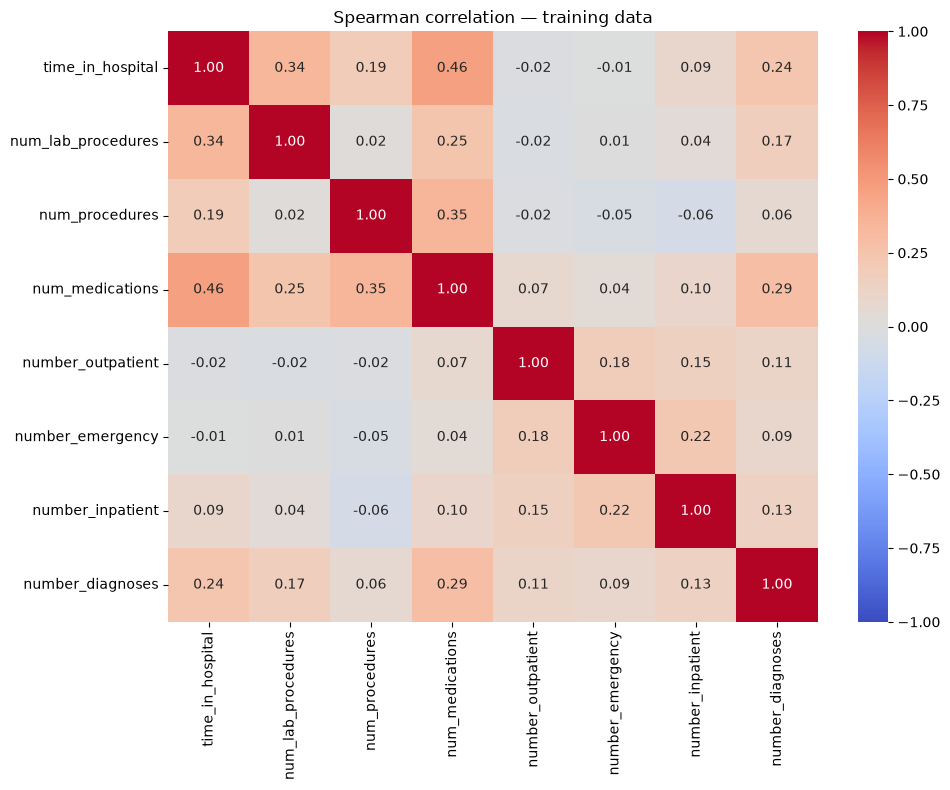

In [2]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

correlation = train_df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Spearman correlation — training data")
plt.tight_layout()
plt.show()

### Compare numerical features with the binary target

Display each feature's Spearman association with target, where 1 means readmission within fewer than 30 days. The sign indicates the direction of the observed monotonic association. Small coefficients do not rule out predictive information, and none of these correlations establishes causality.

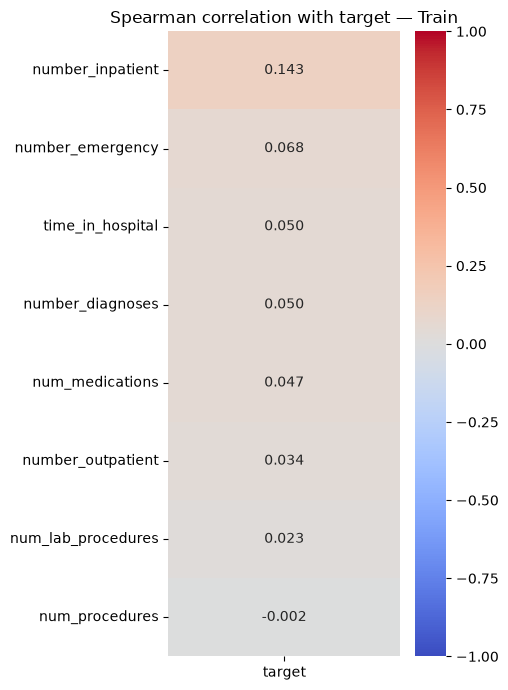

In [3]:
target_corr = (
    train_df[numeric_cols + ["target"]]
    .corr(method="spearman")[["target"]]
    .drop(index="target")
    .sort_values("target", ascending=False)
)

plt.figure(figsize=(5, 7))

sns.heatmap(
    target_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Spearman correlation with target — Train")
plt.tight_layout()
plt.show()

### Summarize previous inpatient visits

For exploration, group previous inpatient visits into 0, 1, 2, and 3+. Count stays and positive outcomes, then compute the percentage positive within each group. These temporary bins do not replace the original predictor. Rates describe stays, and repeated stays from a patient are not independent observations.

In [4]:
inpatient_group = pd.cut(
    train_df["number_inpatient"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=["0", "1", "2", "3+"],
)

inpatient_summary = (
    train_df.groupby(inpatient_group, observed=True)["target"]
    .agg(stays="size", positives="sum", readmission_rate="mean")
)

inpatient_summary["readmission_percent"] = (
    inpatient_summary["readmission_rate"] * 100
)

inpatient_summary[["stays", "positives", "readmission_percent"]].round(2)

,stays,positives,readmission_percent
number_inpatient,,,
0,46611,3951,8.48
1,13332,1752,13.14
2,5187,943,18.18
3+,4814,1261,26.19


### Observations: previous inpatient visits and readmission — Train only

- Observed readmission rates increase with previous inpatient visits:
  - 0 visits: 8.48% (46,611 stays).
  - 1 visit: 13.14% (13,332 stays).
  - 2 visits: 18.18% (5,187 stays).
  - 3+ visits: 26.19% (4,814 stays).
- The 3+ group has approximately three times the observed rate of the zero-visit group.
- This descriptive association does not establish causality or individual risk.
- A weak overall Spearman correlation (0.143) does not rule out useful predictive information.
- Grouping is for exploration only; the original feature remains unchanged.

### Summarize emergency and outpatient visit history

Apply the same temporary bins to previous emergency and outpatient visits. Compare both the group sizes and observed readmission percentages; a high rate in a small group is less stable. Original numerical predictors remain unchanged.

In [5]:
for column in ["number_emergency", "number_outpatient"]:
    groups = pd.cut(
        train_df[column],
        bins=[-1, 0, 1, 2, float("inf")],
        labels=["0", "1", "2", "3+"],
    )

    summary = (
        train_df.groupby(groups, observed=True)["target"]
        .agg(stays="size", positives="sum", rate="mean")
    )
    summary["readmission_percent"] = summary.pop("rate") * 100

    print(f"\n{column}")
    print(summary.round(2))


number_emergency
                  stays  positives  readmission_percent
number_emergency                                       
0                 62098       6563                10.57
1                  5280        770                14.58
2                  1372        261                19.02
3+                 1194        313                26.21

number_outpatient
                   stays  positives  readmission_percent
number_outpatient                                       
0                  58431       6320                10.82
1                   5802        821                14.15
2                   2483        335                13.49
3+                  3228        431                13.35


### Observations: previous emergency and outpatient visits — Train only

- Emergency visits show an increasing observed readmission rate: 10.57%, 14.58%, 19.02%, and 26.21% for 0, 1, 2, and 3+ previous visits, respectively.
- Outpatient visits show a different pattern: 10.82%, 14.15%, 13.49%, and 13.35% across the same groups. The rate does not increase consistently with visit count.
- These are descriptive associations, not evidence of causality.
- Groups contain different numbers of stays; uncertainty has not been quantified.
- Grouping is for exploration only. Original numerical features are retained.

### Compare numerical distributions by outcome

Use boxplots to compare five numerical features between target 0 and target 1. Medians, spread, and distribution overlap provide context beyond a single correlation coefficient. Boxplot outliers are not automatically removed, and visual separation does not establish model performance.

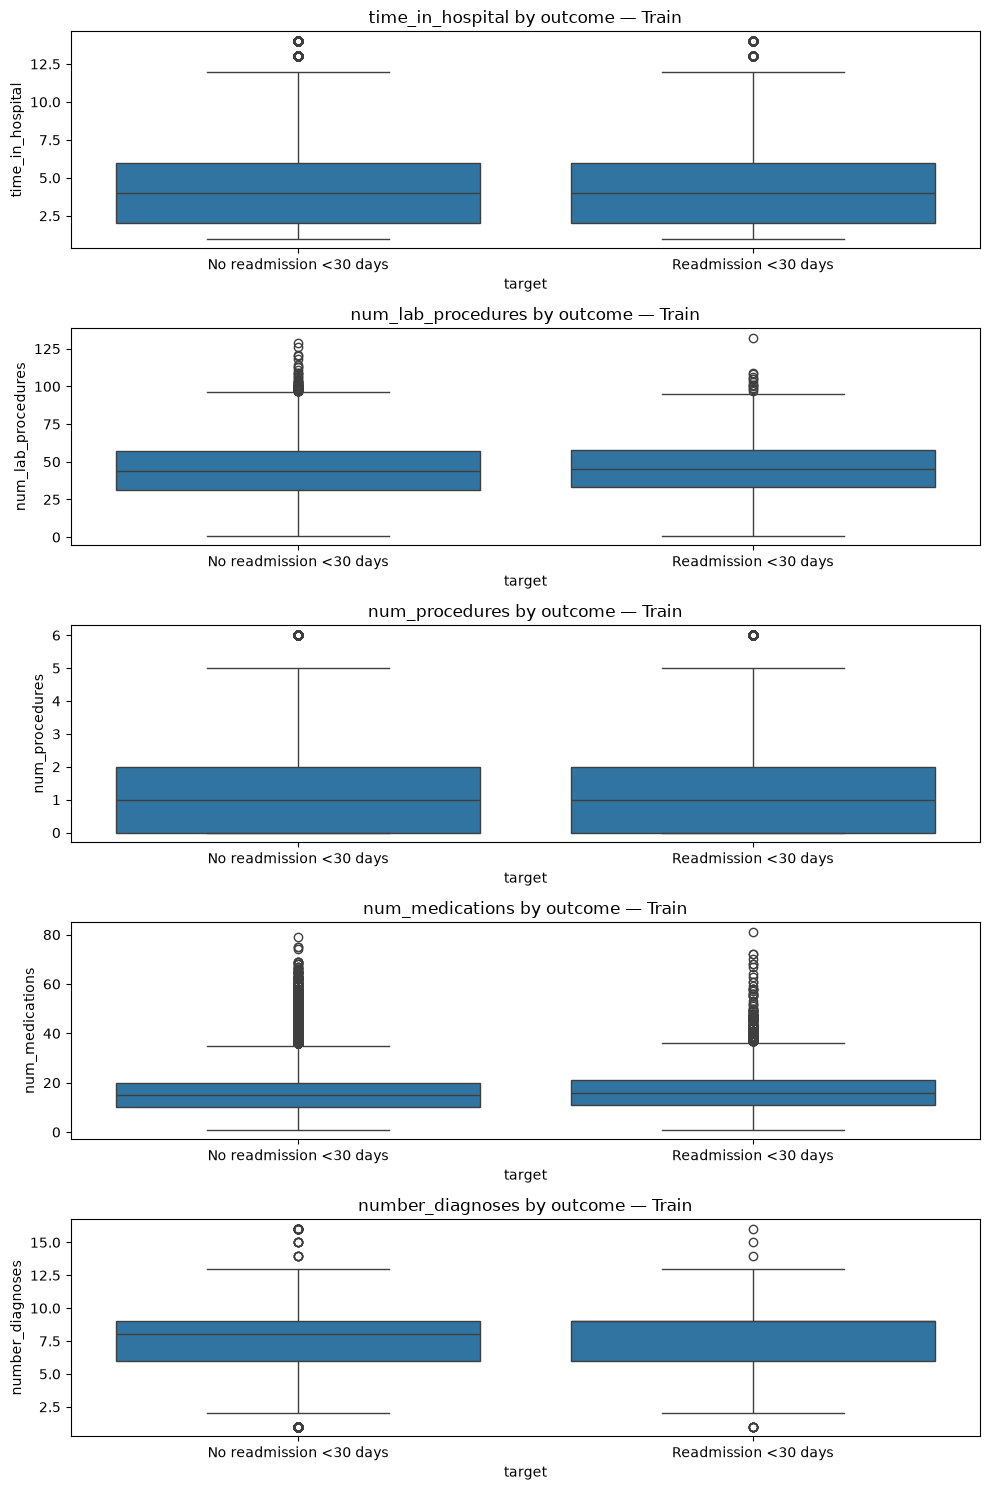

In [6]:
columns_to_compare = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_diagnoses",
]

fig, axes = plt.subplots(
    len(columns_to_compare), 1,
    figsize=(10, 3 * len(columns_to_compare)),
)

for ax, column in zip(axes, columns_to_compare):
    sns.boxplot(
        data=train_df,
        x="target",
        y=column,
        order=[0, 1],
        ax=ax,
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No readmission <30 days", "Readmission <30 days"])
    ax.set_title(f"{column} by outcome — Train")

plt.tight_layout()
plt.show()

### Summarize demographic groups

Report stay counts, positive outcomes, and observed readmission percentages for age, gender, and race. dropna=False retains missing group values in this descriptive summary. These are outcome rates, not a fairness audit of predictions; small groups require particular caution.

In [7]:
for column in ["age", "gender", "race"]:
    summary = (
        train_df.groupby(column, dropna=False, observed=True)["target"]
        .agg(stays="size", positives="sum", readmission_rate="mean")
    )

    summary["readmission_percent"] = (
        summary.pop("readmission_rate") * 100
    ).round(2)

    print(f"\n{column}:")
    print(summary)


age:
          stays  positives  readmission_percent
age                                            
[0-10)      103          2                 1.94
[10-20)     503         34                 6.76
[20-30)    1179        181                15.35
[30-40)    2687        293                10.90
[40-50)    6597        670                10.16
[50-60)   11951       1170                 9.79
[60-70)   15518       1737                11.19
[70-80)   17839       2144                12.02
[80-90)   11688       1452                12.42
[90-100)   1879        224                11.92

gender:
                 stays  positives  readmission_percent
gender                                                
Female           37838       4343                11.48
Male             32104       3564                11.10
Unknown/Invalid      2          0                 0.00

race:
                 stays  positives  readmission_percent
race                                                  
AfricanAmerican  

### Demographic attributes and readmission — training data

- Readmission rates vary across age groups without a consistently
  increasing pattern. The highest observed rate is 15.35% for ages
  [20-30]. The [0-10] group contains only two positive outcomes,
  so its rate should be interpreted cautiously.
- Female and male readmission rates are 11.48% and 11.10%,
  respectively, a descriptive difference of 0.38 percentage points.
  The Unknown/Invalid group contains only two stays and does not
  support reliable comparisons.
- Among recorded race categories, readmission rates range from
  10.03% to 11.51%. Missing race values account for 1,600 stays,
  with a readmission rate of 8.19%, and remain a separate group.
- These rates describe observed outcomes per hospital stay.
  They do not establish causality, statistical significance,
  or fairness of model predictions.
- Patients may contribute multiple stays; these observations
  are not necessarily independent.

### Compare laboratory and treatment categories

Summarize A1Cresult, max_glu_serum, medication changes, and diabetes medication status. "None" is the laboratory test-not-performed category, not a normal result. The denominator includes all stays in each category, including missing categories when present.

In [8]:
columns_to_compare = [
    "A1Cresult",
    "max_glu_serum",
    "change",
    "diabetesMed",
]

for column in columns_to_compare:
    summary = (
        train_df.groupby(column, dropna=False, observed=True)["target"]
        .agg(stays="size", positives="sum", readmission_rate="mean")
    )

    summary["readmission_percent"] = (
        summary.pop("readmission_rate") * 100
    ).round(2)

    print(f"\n{column}:")
    print(summary)


A1Cresult:
           stays  positives  readmission_percent
A1Cresult                                       
>7          2684        261                 9.72
>8          5692        577                10.14
None       58106       6721                11.57
Norm        3462        348                10.05

max_glu_serum:
               stays  positives  readmission_percent
max_glu_serum                                       
>200            1006        122                12.13
>300             840        124                14.76
None           66258       7435                11.22
Norm            1840        226                12.28

change:
        stays  positives  readmission_percent
change                                       
Ch      32259       3864                11.98
No      37685       4043                10.73

diabetesMed:
             stays  positives  readmission_percent
diabetesMed                                       
No           16067       1580                 9.83


### Laboratory results, diabetes treatment, and readmission — training data

- For A1Cresult, stays without a recorded test (None) have a
  readmission rate of 11.57%, compared with 9.72–10.14% across
  the other categories.
- For max_glu_serum, the >300 category has the highest observed
  rate at 14.76%. Rates do not increase consistently across
  the tested categories.
- Stays with a change in diabetes medication have a rate of
  11.98%, compared with 10.73% without a change.
- Stays with diabetes medication prescribed have a rate of
  11.74%, compared with 9.83% without a prescription.
- None indicates that the laboratory test was not performed.
  It is retained as a distinct category.
- These comparisons describe associations, not causal effects.
  Differences may reflect patient characteristics, illness severity,
  or care decisions. Statistical significance has not been assessed.

### Compare admission and discharge categories

Treat admission and discharge codes as categorical identifiers, not quantities. Review rates together with counts and use data/IDS_mapping.csv for category meanings. Discharge information is eligible here because the prediction time is defined as hospital discharge.

In [9]:
columns_to_compare = [
    "admission_type_id",
    "admission_source_id",
    "discharge_disposition_id",
]

for column in columns_to_compare:
    summary = (
        train_df.groupby(column, dropna=False, observed=True)["target"]
        .agg(stays="size", positives="sum", readmission_rate="mean")
    )

    summary["readmission_percent"] = (
        summary.pop("readmission_rate") * 100
    ).round(2)

    print(f"\n{column}:")
    print(summary.sort_values("stays", ascending=False))


admission_type_id:
                   stays  positives  readmission_percent
admission_type_id                                       
1                  36880       4294                11.64
3                  13079       1374                10.51
2                  12795       1432                11.19
6                   3697        445                12.04
5                   3245        344                10.60
8                    226         17                 7.52
7                     14          0                 0.00
4                      8          1                12.50

admission_source_id:
                     stays  positives  readmission_percent
admission_source_id                                       
7                    39213       4633                11.81
1                    20502       2194                10.70
17                    4698        514                10.94
4                     2206        215                 9.75
6                     1601        

### Admission and discharge categories — training data

- Readmission rates are 11.64% for emergency admissions,
  11.19% for urgent admissions, and 10.51% for elective admissions.
- Admissions through the emergency room have a rate of 11.81%,
  compared with 10.70% for physician referrals.
- Discharge destinations show larger descriptive differences:
  home discharges have a rate of 9.25%, skilled nursing facility
  transfers 14.42%, and rehabilitation facility transfers 27.68%.
- High rates in small categories require caution. For example,
  discharge code 12 has a rate of 100%, based on only two stays.
- Codes representing NULL, Not Available, or Not Mapped indicate
  unavailable information and must not be treated as ordinary
  clinical categories when interpreting results.
- These associations do not establish causality or predictive
  performance. Discharge destination may reflect differences
  in patient condition and care needs.
- Discharge information is eligible as a predictor only for
  predictions made at discharge, as defined for this baseline.

## 3. Feature definition and preprocessing

### Review available columns

Inspect the training schema before selecting inputs. Outcome fields and identifiers must remain distinguishable from predictors. The following feature decisions use Train; Test is not loaded in this notebook.

In [10]:
print(train_df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'target']


### Separate predictors from the target

Exclude target and its source readmitted to prevent direct target leakage. Exclude encounter_id and patient_nbr because they identify records and patients. Drop examide and citoglipton, which are constant in Train. Keep eight numerical features; treat the other 36 inputs as categorical, including numeric category codes. The assertions check that every predictor belongs to exactly one feature list.

Demographic attributes remain predictors in this experimental baseline and must also remain available for the later fairness audit.

In [11]:
excluded_columns = [
    "target",
    "readmitted",
    "encounter_id",
    "patient_nbr",
    "examide",
    "citoglipton",
]

X_train = train_df.drop(columns=excluded_columns).copy()
y_train = train_df["target"].copy()

numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

print("Input shape:", X_train.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

assert set(numeric_features).isdisjoint(categorical_features)
assert set(numeric_features + categorical_features) == set(X_train.columns)

Input shape: (69944, 44)
Numeric features: 8
Categorical features: 36


### Load modeling and tracking libraries

Import LightGBM and MLflow and print their installed versions. LightGBM trains the baseline; MLflow records experiment settings, metrics, and saved artifacts. Both packages are required for this notebook.

In [12]:
import lightgbm as lgb
import mlflow

print("LightGBM:", lgb.__version__)
print("MLflow:", mlflow.__version__)

LightGBM: 4.7.0
MLflow: 3.17.2


### Learn categorical levels from Train

Convert the 36 categorical predictors to pandas category dtype using Train values only. Keep numerical features unchanged. LightGBM handles missing feature values directly, so this baseline does not fit an imputer or scaler. The assertions verify that conversion preserves the input shape and target alignment.

In [13]:
X_train_lgb = X_train.copy()

for column in categorical_features:
    X_train_lgb[column] = X_train_lgb[column].astype("category")

print("Categorical columns:",
      X_train_lgb.select_dtypes(include="category").shape[1])
print("Total missing values:",
      X_train_lgb.isna().sum().sum())

assert X_train_lgb.shape == X_train.shape
assert X_train_lgb.index.equals(y_train.index)

Categorical columns: 36
Total missing values: 64950


### Prepare Validation using the training schema

Load Validation with the same CSV parsing policy as Train, select the same feature columns in the same order, and reuse Train's category levels. Values unseen during training are counted and converted to missing values. Validation never defines new training categories.

In [15]:
val_df = pd.read_csv(
    "data/splits/validation.csv",
    keep_default_na=False,
    na_values=[""],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
    },
    low_memory=False,
)


X_val_lgb = val_df.loc[:, X_train_lgb.columns].copy()
y_val = val_df["target"].copy()

for column in categorical_features:
    categories = X_train_lgb[column].cat.categories
    values = X_val_lgb[column]

    unseen = values.notna() & ~values.isin(categories)

    if unseen.any():
        print(f"{column}: {unseen.sum()} unseen values")

    cleaned_values = values.where(~unseen)

    X_val_lgb[column] = pd.Categorical(
        cleaned_values,
        categories=categories,
    )

assert X_val_lgb.columns.equals(X_train_lgb.columns)
assert X_val_lgb.index.equals(y_val.index)

print("Validation inputs:", X_val_lgb.shape)
print("Validation target:", y_val.shape)

diag_1: 28 unseen values
diag_2: 28 unseen values
diag_3: 44 unseen values
acarbose: 3 unseen values
Validation inputs: (15172, 44)
Validation target: (15172,)


### Verify prepared inputs

Require matching categorical dtypes and category ordering across Train and Validation. Check that input row counts match their respective targets. These checks supplement the patient-separation checks performed in exploration.ipynb.

In [16]:
for column in categorical_features:
    assert X_train_lgb[column].dtype == X_val_lgb[column].dtype
    assert X_train_lgb[column].cat.categories.equals(
        X_val_lgb[column].cat.categories
    )

assert len(X_train_lgb) == len(y_train)
assert len(X_val_lgb) == len(y_val)

print("Training and validation inputs are ready.")

Training and validation inputs are ready.


## 4. Initial LightGBM baseline — 31 leaves

### Train with early stopping

Fit a binary classifier on Train with up to 1,000 boosting iterations, a learning rate of 0.05, and 31 leaves. Monitor validation average precision and stop after 50 iterations without improvement. The chosen iteration therefore depends on Validation. The seed and deterministic settings support repeatability within a compatible environment.

In [17]:
model = lgb.LGBMClassifier(
    objective="binary",
    metric="average_precision",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
    deterministic=True,
    force_col_wise=True,
)

model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=50),
    ],
)

print("Best iteration:", model.best_iteration_)
print("Best validation scores:", model.best_score_)

c:\Users\A TO Z\projects\healthequity-agent\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[50]	valid_0's average_precision: 0.221243
[100]	valid_0's average_precision: 0.21596
Early stopping, best iteration is:
[53]	valid_0's average_precision: 0.221439
Best iteration: 53
Best validation scores: defaultdict(<class 'collections.OrderedDict'>, {'valid_0': OrderedDict({'average_precision': np.float64(0.22143882837738968)})})


### Evaluate validation probability scores

Generate positive-class probabilities. Compare average precision with the positive prevalence as a no-skill ranking reference; higher AP and ROC-AUC are better. Lower Brier score means lower mean squared probability error, but does not by itself prove calibration. These are development results because Validation also supports early stopping.

In [ ]:
val_scores = model.predict_proba(X_val_lgb)[:, 1]

print(f"Positive prevalence: {y_val.mean():.4f}")
print(f"Average precision: {average_precision_score(y_val, val_scores):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, val_scores):.4f}")
print(f"Brier score: {brier_score_loss(y_val, val_scores):.4f}")

Positive prevalence: 0.1152
Average precision: 0.2214
ROC-AUC: 0.6696
Brier score: 0.0974


### Inspect the default threshold of 0.5

Convert scores to binary labels at 0.5 and inspect the confusion matrix, precision, recall, F1, and predicted-positive rate. With imbalanced outcomes, this threshold can miss most positives. zero_division=0 is used for these exploratory summaries; the audit's separate undefined-metric policy still needs implementation.

In [ ]:
val_predictions = (val_scores >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val, val_predictions, labels=[0, 1]
).ravel()

print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

print(f"Precision: {precision_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"F1: {f1_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"Predicted positive rate: {val_predictions.mean():.4f}")

True negatives:  13419
False positives: 5
False negatives: 1746
True positives:  2
Precision: 0.2857
Recall: 0.0011
F1: 0.0023
Predicted positive rate: 0.0005


### Explore coarse operating thresholds

Compare several thresholds to show the tradeoff between precision, recall, false positives, false negatives, and the percentage flagged. Lower thresholds generally flag more stays. This is a development comparison, not a clinically validated operating policy.

In [20]:
threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50]:
    predictions = (val_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "flagged_percent": predictions.mean() * 100,
        "false_positives": fp,
        "false_negatives": fn,
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(4))

,threshold,precision,recall,f1,flagged_percent,false_positives,false_negatives
0,0.05,0.1240,0.9668,0.2199,89.8102,11936,58
1,0.10,0.1668,0.6568,0.2660,45.3731,5736,600
2,0.15,0.2074,0.4010,0.2734,22.2779,2679,1047
3,0.20,0.2644,0.2391,0.2511,10.4205,1163,1330
4,0.25,0.3212,0.1316,0.1867,4.7192,486,1518
5,0.30,0.3853,0.0721,0.1214,2.1553,201,1622
6,0.50,0.2857,0.0011,0.0023,0.0461,5,1746


### Search a finer validation threshold grid

Evaluate thresholds from 0.05 through 0.30 in steps of 0.005. Rank by F1, using the larger threshold to break exact ties. This grid defines the search space; the chosen threshold is optimal only among evaluated values under this rule.

In [ ]:
threshold_results = []

for threshold in np.arange(0.05, 0.301, 0.005):
    predictions = (val_scores >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "flagged_percent": predictions.mean() * 100,
    })

threshold_table = pd.DataFrame(threshold_results)

display(
    threshold_table.sort_values(
        ["f1", "threshold"],
        ascending=[False, False],
    ).head(10).round(4)
)

,threshold,precision,recall,f1,flagged_percent
17,0.135,0.1975,0.4708,0.2782,27.4717
22,0.160,0.2227,0.3701,0.2781,19.1471
23,0.165,0.2286,0.3535,0.2777,17.8157
18,0.140,0.2001,0.4457,0.2761,25.6657
24,0.170,0.2347,0.3347,0.2759,16.4316
16,0.130,0.1917,0.4914,0.2758,29.5347
19,0.145,0.2042,0.4245,0.2757,23.9520
25,0.175,0.2414,0.3204,0.2753,15.2913
21,0.155,0.2139,0.3827,0.2745,20.6103
20,0.150,0.2074,0.4010,0.2734,22.2779


### Select the initial model's threshold

Store the best grid threshold and regenerate validation labels from it. The recorded initial choice is 0.135. F1 balances precision and recall but does not encode clinical costs or capacity limits. These variables continue to refer to the original 31-leaf model.

In [22]:
best_threshold_row = threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

decision_threshold = float(best_threshold_row["threshold"])

val_predictions = (
    val_scores >= decision_threshold
).astype(int)

print(f"Selected threshold: {decision_threshold:.3f}")
print(f"Validation F1: {best_threshold_row['f1']:.4f}")

Selected threshold: 0.135
Validation F1: 0.2782


## 5. Track and preserve the initial baseline

### Configure local MLflow tracking

Use mlflow.db for experiment metadata and mlartifacts for model files under the repository root. Reuse the readmission-baseline experiment if it exists; otherwise create it with an explicit artifact location. These outputs are local and excluded from Git.

In [23]:
from pathlib import Path

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

assert (project_root / "app").is_dir(), "Check the project path."

database_path = project_root / "mlflow.db"
artifact_path = project_root / "mlartifacts"

mlflow.set_tracking_uri(
    f"sqlite:///{database_path.as_posix()}"
)

experiment_name = "readmission-baseline"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    mlflow.create_experiment(
        experiment_name,
        artifact_location=artifact_path.as_uri(),
    )

mlflow.set_experiment(experiment_name)

print("MLflow experiment is ready.")

2026/10/29 16:58:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/29 16:58:04 INFO mlflow.store.db.utils: Updating database tables


MLflow experiment is ready.


### Log initial-model parameters and metrics

Create a run for the original baseline and record training parameters, best iteration, selected threshold, dataset sizes, library versions, and validation metrics. Save the generated run ID for later artifact operations. Re-running this cell creates another run; historical run IDs in the notes refer to the previously recorded execution.

In [24]:
validation_metrics = {
    "val_average_precision": average_precision_score(y_val, val_scores),
    "val_roc_auc": roc_auc_score(y_val, val_scores),
    "val_brier_score": brier_score_loss(y_val, val_scores),
    "val_precision": precision_score(
        y_val, val_predictions, zero_division=0
    ),
    "val_recall": recall_score(
        y_val, val_predictions, zero_division=0
    ),
    "val_f1": f1_score(
        y_val, val_predictions, zero_division=0
    ),
    "val_flagged_rate": float(val_predictions.mean()),
}

with mlflow.start_run(run_name="lightgbm-baseline") as run:
    mlflow.log_params(model.get_params())

    mlflow.log_params({
        "best_iteration": model.best_iteration_,
        "decision_threshold": decision_threshold,
        "threshold_selection": "max_validation_f1_grid",
        "early_stopping_rounds": 50,
        "train_rows": len(X_train_lgb),
        "validation_rows": len(X_val_lgb),
        "feature_count": X_train_lgb.shape[1],
        "lightgbm_version": lgb.__version__,
        "mlflow_version": mlflow.__version__,
    })

    mlflow.log_metrics(validation_metrics)

    mlflow.set_tags({
        "split_method": "patient_group_split",
        "purpose": "experimental_baseline",
        "evaluation_dataset": "validation",
    })

    baseline_run_id = run.info.run_id

print("Saved run:", baseline_run_id)

Saved run: 8f9049f56e8943c19814c6a4214db121


### Read back the recorded run

Fetch the initial run from MLflow and inspect its status, threshold, iteration, and metrics. This verifies that experiment metadata was persisted; the model artifact is saved in the following cell.

In [25]:
saved_run = mlflow.get_run(baseline_run_id)

print("Status:", saved_run.info.status)
print("Threshold:", saved_run.data.params["decision_threshold"])
print("Best iteration:", saved_run.data.params["best_iteration"])
print("Validation F1:", saved_run.data.metrics["val_f1"])
print("Validation ROC-AUC:", saved_run.data.metrics["val_roc_auc"])

Status: FINISHED
Threshold: 0.13499999999999995
Best iteration: 53
Validation F1: 0.2782285327924273
Validation ROC-AUC: 0.6696404310528224


### Save the original model and preprocessing configuration

Export the booster at its best iteration and save its feature order, numerical and categorical feature lists, training category levels, positive-class definition, and threshold. Use a temporary file only for the export, then log the artifact and JSON configuration under the existing run.

In [30]:
baseline_config = {
    "decision_threshold": decision_threshold,
    "best_iteration": model.best_iteration_,
    "feature_columns": X_train_lgb.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "categories": {
        column: X_train_lgb[column].cat.categories.tolist()
        for column in categorical_features
    },
    "unseen_category_policy": "convert_to_missing",
    "positive_class": "readmission within less than 30 days",
}

with mlflow.start_run(run_id=baseline_run_id):
    with TemporaryDirectory() as temporary_directory:
        model_path = Path(temporary_directory) / "model.txt"

        model.booster_.save_model(
            str(model_path),
            num_iteration=model.best_iteration_,
        )

        mlflow.log_artifact(
            str(model_path),
            artifact_path="baseline",
        )

    mlflow.log_dict(
        baseline_config,
        "baseline/config.json",
    )

print("Baseline model and configuration saved.")

Baseline model and configuration saved.


### Verify the original model artifact

Reload the saved booster and compare its validation scores with the in-memory model using tight numerical tolerances. This check reuses the prepared Validation table; the selected model's later check also rebuilds preprocessing from its saved configuration.

In [31]:
saved_model_path = mlflow.artifacts.download_artifacts(
    run_id=baseline_run_id,
    artifact_path="baseline/model.txt",
)

loaded_model = lgb.Booster(model_file=saved_model_path)

loaded_val_scores = loaded_model.predict(X_val_lgb)

np.testing.assert_allclose(
    loaded_val_scores,
    val_scores,
    rtol=1e-10,
    atol=1e-12,
)

print("Saved model reproduces the original predictions.")

Saved model reproduces the original predictions.


### Recorded results: initial 31-leaf baseline

- Inputs: 44 features (8 numeric and 36 categorical).
- Patient-disjoint training and validation sets.
- Best boosting iteration: 53, selected using early stopping
  on validation average precision.
- Validation average precision: 0.2214.
- Validation ROC-AUC: 0.6696.
- Validation Brier score: 0.0974.
- Decision threshold: 0.135, selected by maximizing validation
  F1 over the evaluated threshold grid.
- At this threshold: precision = 0.1975, recall = 0.4708,
  F1 = 0.2782, and 27.47% of stays are flagged.
- Validation was used for model and threshold selection;
  these are development results, not final test estimates.
- The model remains an experimental baseline. Fairness and
  probability calibration have not yet been evaluated.
- MLflow run ID: 8f9049f56e8943c19814c6a4214db121.

## 6. Compare a simpler baseline

### Review the Train–Validation performance gap

Compare the original model's ranking metrics and probability error on Train and Validation. Better training performance can indicate overfitting, but a gap alone does not prove its cause. This motivates one controlled comparison with fewer leaves while leaving Test reserved.

In [32]:
train_scores = model.predict_proba(X_train_lgb)[:, 1]

performance_comparison = pd.DataFrame({
    "dataset": ["Train", "Validation"],
    "average_precision": [
        average_precision_score(y_train, train_scores),
        average_precision_score(y_val, val_scores),
    ],
    "roc_auc": [
        roc_auc_score(y_train, train_scores),
        roc_auc_score(y_val, val_scores),
    ],
    "brier_score": [
        brier_score_loss(y_train, train_scores),
        brier_score_loss(y_val, val_scores),
    ],
})

display(performance_comparison.round(4))

,dataset,average_precision,roc_auc,brier_score
0,Train,0.3646,0.7829,0.0886
1,Validation,0.2214,0.6696,0.0974


### Train a 15-leaf alternative

Copy the original settings and change only num_leaves from 31 to 15. Train on the same inputs with the same validation metric and early-stopping rule, then generate separate validation scores. A smaller tree limits complexity; the result still requires validation rather than an assumption of better generalization.

In [33]:
simpler_params = model.get_params().copy()
simpler_params["num_leaves"] = 15

simpler_model = lgb.LGBMClassifier(**simpler_params)

simpler_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=50),
    ],
)

simpler_val_scores = simpler_model.predict_proba(X_val_lgb)[:, 1]

print("Best iteration:", simpler_model.best_iteration_)
print(
    "Validation AP:",
    round(average_precision_score(y_val, simpler_val_scores), 4),
)
print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val, simpler_val_scores), 4),
)
print(
    "Validation Brier:",
    round(brier_score_loss(y_val, simpler_val_scores), 4),
)

c:\Users\A TO Z\projects\healthequity-agent\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[50]	valid_0's average_precision: 0.221439
[100]	valid_0's average_precision: 0.219382
Early stopping, best iteration is:
[54]	valid_0's average_precision: 0.222108
Best iteration: 54
Validation AP: 0.2221
Validation ROC-AUC: 0.6716
Validation Brier: 0.0974


### Compare both models on Validation

Compare best iteration, average precision, ROC-AUC, and Brier score. Higher AP and ROC-AUC and lower Brier score are preferred. The recorded 15-leaf model improves all three metrics slightly, so it is selected as the experimental baseline. No statistical significance test was performed, and these comparisons are not final Test estimates.

In [34]:
model_comparison = pd.DataFrame({
    "model": ["Original — 31 leaves", "Simpler — 15 leaves"],
    "best_iteration": [
        model.best_iteration_,
        simpler_model.best_iteration_,
    ],
    "validation_ap": [
        average_precision_score(y_val, val_scores),
        average_precision_score(y_val, simpler_val_scores),
    ],
    "validation_roc_auc": [
        roc_auc_score(y_val, val_scores),
        roc_auc_score(y_val, simpler_val_scores),
    ],
    "validation_brier": [
        brier_score_loss(y_val, val_scores),
        brier_score_loss(y_val, simpler_val_scores),
    ],
})

model_comparison.round(5)

,model,best_iteration,validation_ap,validation_roc_auc,validation_brier
0,Original — 31 leaves,53,0.22144,0.66964,0.09744
1,Simpler — 15 leaves,54,0.22211,0.67157,0.09738


## 7. Select and preserve the 15-leaf baseline

### Search a threshold for the selected model

Run the same threshold grid and F1 selection rule on simpler_val_scores. Do not transfer the original model's threshold automatically: the alternative has a different score distribution. Precision, recall, F1, and percentage flagged are calculated from its own validation predictions.

In [35]:
simpler_threshold_results = []

for threshold in np.arange(0.05, 0.301, 0.005):
    predictions = (simpler_val_scores >= threshold).astype(int)

    simpler_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "flagged_percent": predictions.mean() * 100,
    })

simpler_threshold_table = pd.DataFrame(simpler_threshold_results)

simpler_threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).head(5).round(4)

,threshold,precision,recall,f1,flagged_percent
19,0.145,0.2106,0.4273,0.2822,23.3786
17,0.135,0.2007,0.4743,0.2821,27.2212
18,0.140,0.2051,0.4485,0.2815,25.1977
20,0.150,0.2154,0.4045,0.2811,21.6385
16,0.130,0.1942,0.4937,0.2787,29.2974


### Store the selected operating threshold

Select the largest threshold among exact F1 ties and generate labels for the simpler model. The recorded choice is 0.145 with validation F1 of approximately 0.2822. Keep these variables separate from the original baseline's scores, labels, and threshold.

In [36]:
simpler_best_threshold_row = simpler_threshold_table.sort_values(
    ["f1", "threshold"],
    ascending=[False, False],
).iloc[0]

simpler_decision_threshold = float(
    simpler_best_threshold_row["threshold"]
)

simpler_val_predictions = (
    simpler_val_scores >= simpler_decision_threshold
).astype(int)

print(f"Selected threshold: {simpler_decision_threshold:.3f}")
print(f"Validation F1: {simpler_best_threshold_row['f1']:.4f}")

Selected threshold: 0.145
Validation F1: 0.2822


### Log the selected baseline as a separate MLflow run

Record the simpler model's parameters, versions, best iteration, threshold, and validation metrics. The selected_baseline tag identifies this run's role in the current comparison; it is descriptive metadata, not a deployment or registry promotion. Re-running this cell creates a new run ID.

In [37]:
simpler_validation_metrics = {
    "val_average_precision": average_precision_score(
        y_val, simpler_val_scores
    ),
    "val_roc_auc": roc_auc_score(y_val, simpler_val_scores),
    "val_brier_score": brier_score_loss(y_val, simpler_val_scores),
    "val_precision": precision_score(
        y_val, simpler_val_predictions, zero_division=0
    ),
    "val_recall": recall_score(
        y_val, simpler_val_predictions, zero_division=0
    ),
    "val_f1": f1_score(
        y_val, simpler_val_predictions, zero_division=0
    ),
    "val_flagged_rate": float(simpler_val_predictions.mean()),
}

with mlflow.start_run(run_name="lightgbm-baseline-15-leaves") as run:
    mlflow.log_params(simpler_model.get_params())

    mlflow.log_params({
        "best_iteration": simpler_model.best_iteration_,
        "decision_threshold": simpler_decision_threshold,
        "threshold_selection": "max_validation_f1_grid",
        "early_stopping_rounds": 50,
        "train_rows": len(X_train_lgb),
        "validation_rows": len(X_val_lgb),
        "feature_count": X_train_lgb.shape[1],
        "lightgbm_version": lgb.__version__,
        "mlflow_version": mlflow.__version__,
    })

    mlflow.log_metrics(simpler_validation_metrics)

    mlflow.set_tags({
        "split_method": "patient_group_split",
        "purpose": "experimental_baseline",
        "evaluation_dataset": "validation",
        "selected_baseline": "true",
    })

    simpler_run_id = run.info.run_id

print("Saved run:", simpler_run_id)

Saved run: a68871a678b842828033d442632a63cc


### Save the selected model and configuration

Save the 15-leaf booster and its own threshold together with the training feature schema and category levels. Log both files under the simpler run ID so they remain associated with its metrics. This configuration is required to reconstruct prediction inputs consistently.

In [38]:
simpler_config = {
    "decision_threshold": simpler_decision_threshold,
    "best_iteration": simpler_model.best_iteration_,
    "feature_columns": X_train_lgb.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "categories": {
        column: X_train_lgb[column].cat.categories.tolist()
        for column in categorical_features
    },
    "unseen_category_policy": "convert_to_missing",
    "positive_class": "readmission within less than 30 days",
}

with mlflow.start_run(run_id=simpler_run_id):
    with TemporaryDirectory() as temporary_directory:
        model_path = Path(temporary_directory) / "model.txt"

        simpler_model.booster_.save_model(
            str(model_path),
            num_iteration=simpler_model.best_iteration_,
        )

        mlflow.log_artifact(
            str(model_path),
            artifact_path="baseline",
        )

    mlflow.log_dict(
        simpler_config,
        "baseline/config.json",
    )

print("Simpler model and configuration saved.")

Simpler model and configuration saved.


### Verify the saved model and preprocessing together

Reload both artifacts from the selected run. Rebuild Validation inputs using saved feature order and category levels, explicitly converting unseen categories to missing. Compare scores to the in-memory simpler model, then compare labels using the saved threshold. Both assertions must pass before these artifacts are used downstream.

In [39]:
import json

saved_model_path = mlflow.artifacts.download_artifacts(
    run_id=simpler_run_id,
    artifact_path="baseline/model.txt",
)

saved_config_path = mlflow.artifacts.download_artifacts(
    run_id=simpler_run_id,
    artifact_path="baseline/config.json",
)

with open(saved_config_path, encoding="utf-8") as file:
    loaded_config = json.load(file)

loaded_simpler_model = lgb.Booster(model_file=saved_model_path)

loaded_X_val = val_df[
    loaded_config["feature_columns"]
].copy()

for column in loaded_config["categorical_features"]:
    categories = loaded_config["categories"][column]
    values = loaded_X_val[column]

    loaded_X_val[column] = pd.Categorical(
        values.where(values.isin(categories)),
        categories=categories,
    )

loaded_scores = loaded_simpler_model.predict(loaded_X_val)

np.testing.assert_allclose(
    loaded_scores,
    simpler_val_scores,
    rtol=1e-10,
    atol=1e-12,
)

np.testing.assert_array_equal(
    (loaded_scores >= loaded_config["decision_threshold"]).astype(int),
    simpler_val_predictions,
)

print("Saved model and configuration reproduce the original predictions.")

Saved model and configuration reproduce the original predictions.


## 8. Recorded results and next steps

### Selected baseline — LightGBM with 15 leaves

- Selected the simpler model based on slightly better validation
  average precision, ROC-AUC, and Brier score.
- Best iteration: 54.
- Validation average precision: 0.22211.
- Validation ROC-AUC: 0.67157.
- Validation Brier score: 0.09738.
- Decision threshold: 0.145, selected by maximizing validation F1
  over the evaluated threshold grid.
- At this threshold:
  - Precision: 0.2106.
  - Recall: 0.4273.
  - F1: 0.2822.
  - Flagged stays: 23.38%.
- The improvement is small; statistical significance was not assessed.
- Validation supported model and threshold selection.
  Final performance has not yet been evaluated on Test.
- Model and preprocessing configuration were saved in MLflow.
- Reloading both reproduced the original validation scores and labels.
- MLflow run ID: a68871a678b842828033d442632a63cc.
- Fairness and probability calibration have not yet been evaluated.

### Remaining evaluation work

- Keep the selected model, preprocessing schema, and threshold fixed before final Test evaluation.
- Evaluate overall and per-group performance with the audit's small-group suppression and undefined-metric policies.
- Assess probability calibration and quantify uncertainty with methods that account for repeated stays per patient.
- Record final evaluation results separately from validation-based selection results.

The previous baseline remains preserved for comparison. The selected 15-leaf run and its configuration are the starting artifacts for the next stage.